# CA1 – Machine Learning: Student Academic Performance

**Student:** Richardson da Silva Reboucas (2020272)  
**Programme:** Higher Diploma in Science in Data Analytics for Business  
**Module:** Machine Learning  
**Lecturer:** Dr. Muhammad Iqbal  
**Institution:** CCT College Dublin  

---

This notebook implements the full analysis described in the accompanying report:
- Binary classification (pass/fail) based on G3 ≥ 10
- Exclusion of G1 and G2 to reduce target leakage (early-warning framing)
- Comparison of Logistic Regression and Random Forest
- Stratified 80/20 train-test split + 5-fold stratified CV
- GridSearchCV hyperparameter tuning
- Experiment with 5%, 15% and 25% training subsets

## 1. Imports and setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
pd.set_option('display.max_columns', 50)
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Load and inspect the dataset

Source: Cortez (2008) Student Performance – Portuguese language dataset (UCI).

In [2]:
# Read CSV with semicolon delimiter (as provided by UCI)
df = pd.read_csv('student-por.csv', sep=';')

print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
print(f'\nMissing values: {df.isnull().sum().sum()}')
print(f'Duplicate rows: {df.duplicated().sum()}')
df.head()

Shape: (649, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values: 0
Duplicate rows: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [3]:
# Target definition: pass if G3 >= 10
df['pass'] = (df['G3'] >= 10).astype(int)

print('Target distribution:')
print(df['pass'].value_counts())
print(f'\nPass rate: {df["pass"].mean():.1%}')

print('\nG3 statistics:')
print(df['G3'].describe())

Target distribution:
pass
1    549
0    100
Name: count, dtype: int64

Pass rate: 84.6%

G3 statistics:
count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64


## 3. Feature preparation

- **Target:** `pass` (G3 ≥ 10)
- **Excluded predictors:** G1, G2, G3 (to avoid leakage and keep early-warning framing)
- Remaining: 30 predictors (demographic, family, school support, lifestyle)

In [4]:
# Define predictors and target
X = df.drop(columns=['G3', 'G1', 'G2', 'pass'])
y = df['pass']

print(f'Predictors shape: {X.shape}')
print(f'Target shape: {y.shape}')

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f'\nNumeric features ({len(numeric_features)}): {numeric_features}')
print(f'Categorical features ({len(categorical_features)}): {categorical_features}')

Predictors shape: (649, 30)
Target shape: (649,)

Numeric features (13): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical features (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## 4. Preprocessing pipeline

All preprocessing is placed inside a Pipeline / ColumnTransformer to prevent data leakage.

In [5]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print('Preprocessor defined.')

Preprocessor defined.


## 5. Train-test split (stratified 80/20)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f'Training set: {X_train.shape[0]} rows')
print(f'Test set:     {X_test.shape[0]} rows')
print(f'\nTrain target balance:\n{y_train.value_counts()}')
print(f'\nTest target balance:\n{y_test.value_counts()}')

Training set: 519 rows
Test set:     130 rows

Train target balance:
pass
1    439
0     80
Name: count, dtype: int64

Test target balance:
pass
1    110
0     20
Name: count, dtype: int64


## 6. Model definitions and baseline evaluation

In [7]:
# Logistic Regression pipeline
lr_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Random Forest pipeline
rf_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Fit on training data
lr_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)

print('Both models fitted.')

Both models fitted.


In [8]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    print(f'=== {name} (Test set) ===')
    print(f'Accuracy:  {acc:.3f}')
    print(f'Precision (pass): {prec:.3f}')
    print(f'Recall (pass):    {rec:.3f}')
    print(f'F1 (pass):        {f1:.3f}')
    print(classification_report(y_test, y_pred, target_names=['fail', 'pass']))
    return y_pred

y_pred_lr = evaluate_model('Logistic Regression', lr_pipe, X_test, y_test)
y_pred_rf = evaluate_model('Random Forest', rf_pipe, X_test, y_test)

=== Logistic Regression (Test set) ===
Accuracy:  0.792
Precision (pass): 0.867
Recall (pass):    0.891
F1 (pass):        0.879
              precision    recall  f1-score   support

        fail       0.29      0.25      0.27        20
        pass       0.87      0.89      0.88       110

    accuracy                           0.79       130
   macro avg       0.58      0.57      0.57       130
weighted avg       0.78      0.79      0.79       130

=== Random Forest (Test set) ===
Accuracy:  0.800
Precision (pass): 0.856
Recall (pass):    0.918
F1 (pass):        0.886
              precision    recall  f1-score   support

        fail       0.25      0.15      0.19        20
        pass       0.86      0.92      0.89       110

    accuracy                           0.80       130
   macro avg       0.55      0.53      0.54       130
weighted avg       0.76      0.80      0.78       130



## 7. Cross-validation on training set

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in [('Logistic Regression', lr_pipe), ('Random Forest', rf_pipe)]:
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
    pipe.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, pipe.predict(X_train))
    print(f'{name}:')
    print(f'  CV Accuracy: {acc_scores.mean():.3f} ± {acc_scores.std():.3f}')
    print(f'  CV F1:       {f1_scores.mean():.3f}')
    print(f'  Train Acc:   {train_acc:.3f}')
    print()

Logistic Regression:
  CV Accuracy: 0.861 ± 0.022
  CV F1:       0.920
  Train Acc:   0.898



Random Forest:
  CV Accuracy: 0.865 ± 0.020
  CV F1:       0.925
  Train Acc:   1.000



## 8. Hyperparameter tuning (GridSearchCV) – Random Forest

We tune `n_estimators`, `max_depth` and `min_samples_leaf` using F1 score and 5-fold stratified CV on the training set.

In [10]:
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    rf_pipe,
    param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print(f'Best CV F1: {grid.best_score_:.3f}')

Fitting 5 folds for each of 18 candidates, totalling 90 fits


Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Best CV F1: 0.925


=== Tuned Random Forest (Test set) ===
Accuracy: 0.800
              precision    recall  f1-score   support

        fail       0.25      0.15      0.19        20
        pass       0.86      0.92      0.89       110

    accuracy                           0.80       130
   macro avg       0.55      0.53      0.54       130
weighted avg       0.76      0.80      0.78       130



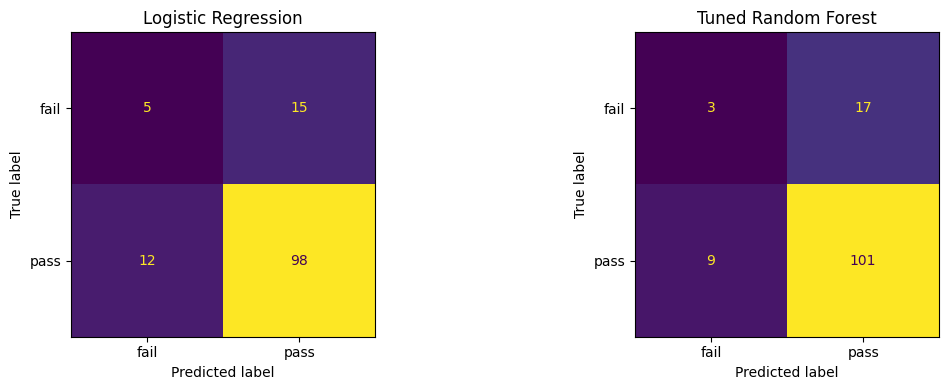

In [11]:
# Evaluate tuned model on held-out test set
y_pred_tuned = grid.predict(X_test)
print('=== Tuned Random Forest (Test set) ===')
print(f'Accuracy: {accuracy_score(y_test, y_pred_tuned):.3f}')
print(classification_report(y_test, y_pred_tuned, target_names=['fail', 'pass']))

# Confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=['fail','pass'], ax=ax[0], colorbar=False)
ax[0].set_title('Logistic Regression')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, display_labels=['fail','pass'], ax=ax[1], colorbar=False)
ax[1].set_title('Tuned Random Forest')
plt.tight_layout()
plt.show()

## 9. Feature importance (tuned Random Forest)

Top 15 features by importance:
   feature  importance
  failures    0.095960
  absences    0.043896
 higher_no    0.043244
 school_GP    0.042315
higher_yes    0.042180
      Walc    0.040151
    famrel    0.037721
     goout    0.037054
  freetime    0.035950
       age    0.034211
 school_MS    0.033325
      Fedu    0.030073
      Medu    0.028384
      Dalc    0.027869
    health    0.025599


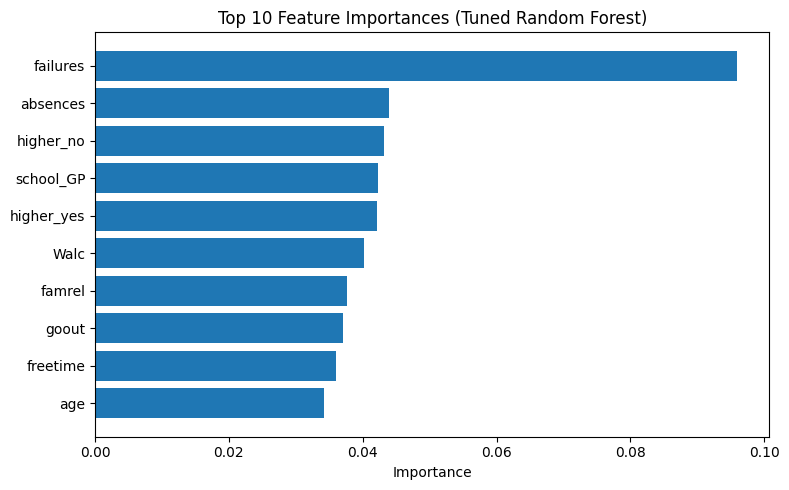

In [12]:
best_rf = grid.best_estimator_
pre = best_rf.named_steps['pre']

cat_names = pre.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
feat_names = list(numeric_features) + list(cat_names)

importances = best_rf.named_steps['clf'].feature_importances_
imp_df = (pd.DataFrame({'feature': feat_names, 'importance': importances})
          .sort_values('importance', ascending=False)
          .reset_index(drop=True))

print('Top 15 features by importance:')
print(imp_df.head(15).to_string(index=False))

plt.figure(figsize=(8, 5))
top10 = imp_df.head(10)
plt.barh(top10['feature'][::-1], top10['importance'][::-1])
plt.title('Top 10 Feature Importances (Tuned Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 10. Training-split experiment (5%, 15%, 25%)

The original dataset is first divided into a stratified 80% development set and a 20% final test set. The three training sizes (5%, 15% and 25%) are then sampled from the 80% development set only. The final test set is kept untouched and is used to evaluate every subset model on the same observations.

For each training size, five-fold stratified cross-validation is performed within that subset. This provides a consistent comparison while avoiding the use of final-test observations during model development. The percentages therefore refer to the full dataset's row count as requested, but the sampled rows come only from the development partition. Small training subsets—especially 5%—produce less stable estimates and should be interpreted cautiously.

In [13]:
subset_results = []
subset_models = {}

# Percentages are calculated against the full dataset, but sampled only
# from X_train. X_test remains untouched until final evaluation.
for frac in [0.05, 0.15, 0.25]:
    n_rows = max(10, int(round(frac * len(df))))
    n_rows = min(n_rows, len(X_train))
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train, train_size=n_rows, stratify=y_train, random_state=42
    )

    print(f"\\n{'='*55}")
    print(f"Training subset: {int(frac*100)}% of full dataset ({len(X_sub)} rows)")
    print(f"Subset class distribution: {y_sub.value_counts().to_dict()}")

    # Five-fold stratified CV is applied only to the selected training subset.
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for name, model in [
        ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42)),
        ('Random Forest', RandomForestClassifier(random_state=42, n_jobs=-1))
    ]:
        pipe = Pipeline([('pre', clone(preprocessor)), ('clf', model)])
        acc_scores = cross_val_score(pipe, X_sub, y_sub, cv=skf, scoring='accuracy')
        f1_scores = cross_val_score(pipe, X_sub, y_sub, cv=skf, scoring='f1')
        pipe.fit(X_sub, y_sub)
        y_subset_test_pred = pipe.predict(X_test)

        row = {
            'Training subset': f'{int(frac*100)}%',
            'Training rows': len(X_sub),
            'Model': name,
            'CV accuracy mean': acc_scores.mean(),
            'CV accuracy std': acc_scores.std(),
            'CV F1 (pass) mean': f1_scores.mean(),
            'Test accuracy': accuracy_score(y_test, y_subset_test_pred),
            'Test F1 (pass)': f1_score(y_test, y_subset_test_pred, zero_division=0),
            'Test recall (fail)': recall_score(y_test, y_subset_test_pred, pos_label=0, zero_division=0),
            'Train accuracy': accuracy_score(y_sub, pipe.predict(X_sub))
        }
        subset_results.append(row)
        subset_models[(frac, name)] = pipe

        print(f"  {name}: CV accuracy={acc_scores.mean():.3f} ± {acc_scores.std():.3f}; "
              f"CV F1(pass)={f1_scores.mean():.3f}; "
              f"held-out test accuracy={row['Test accuracy']:.3f}; "
              f"test fail recall={row['Test recall (fail)']:.3f}")

results_df = pd.DataFrame(subset_results)
display(results_df.round(3))
results_df.to_csv('CA1_Split_Comparison_Results_from_notebook.csv', index=False)
print('Saved comparison results. The same untouched test set was used for all subset sizes.')

\n=======================================================
Training subset: 5% of full dataset (32 rows)
Subset class distribution: {1: 27, 0: 5}


  Logistic Regression: CV accuracy=0.748 ± 0.134; CV F1(pass)=0.848; held-out test accuracy=0.800; test fail recall=0.100


  Random Forest: CV accuracy=0.843 ± 0.012; CV F1(pass)=0.915; held-out test accuracy=0.846; test fail recall=0.000
\n=======================================================
Training subset: 15% of full dataset (97 rows)
Subset class distribution: {1: 82, 0: 15}


  Logistic Regression: CV accuracy=0.826 ± 0.081; CV F1(pass)=0.898; held-out test accuracy=0.769; test fail recall=0.150


  Random Forest: CV accuracy=0.845 ± 0.032; CV F1(pass)=0.915; held-out test accuracy=0.846; test fail recall=0.000
\n=======================================================
Training subset: 25% of full dataset (162 rows)
Subset class distribution: {1: 137, 0: 25}


  Logistic Regression: CV accuracy=0.833 ± 0.051; CV F1(pass)=0.906; held-out test accuracy=0.723; test fail recall=0.300


  Random Forest: CV accuracy=0.845 ± 0.053; CV F1(pass)=0.914; held-out test accuracy=0.831; test fail recall=0.100


,Training subset,Training rows,Model,CV accuracy mean,CV accuracy std,CV F1 (pass) mean,Test accuracy,Test F1 (pass),Test recall (fail),Train accuracy
0,5%,32,Logistic Regression,0.748,0.134,0.848,0.800,0.887,0.10,0.969
1,5%,32,Random Forest,0.843,0.012,0.915,0.846,0.917,0.00,1.000
2,15%,97,Logistic Regression,0.826,0.081,0.898,0.769,0.866,0.15,0.928
3,15%,97,Random Forest,0.845,0.032,0.915,0.846,0.917,0.00,1.000
4,25%,162,Logistic Regression,0.833,0.051,0.906,0.723,0.830,0.30,0.926
5,25%,162,Random Forest,0.845,0.053,0.914,0.831,0.906,0.10,1.000


Saved comparison results. The same untouched test set was used for all subset sizes.


## 11. Visual comparison of subset performance

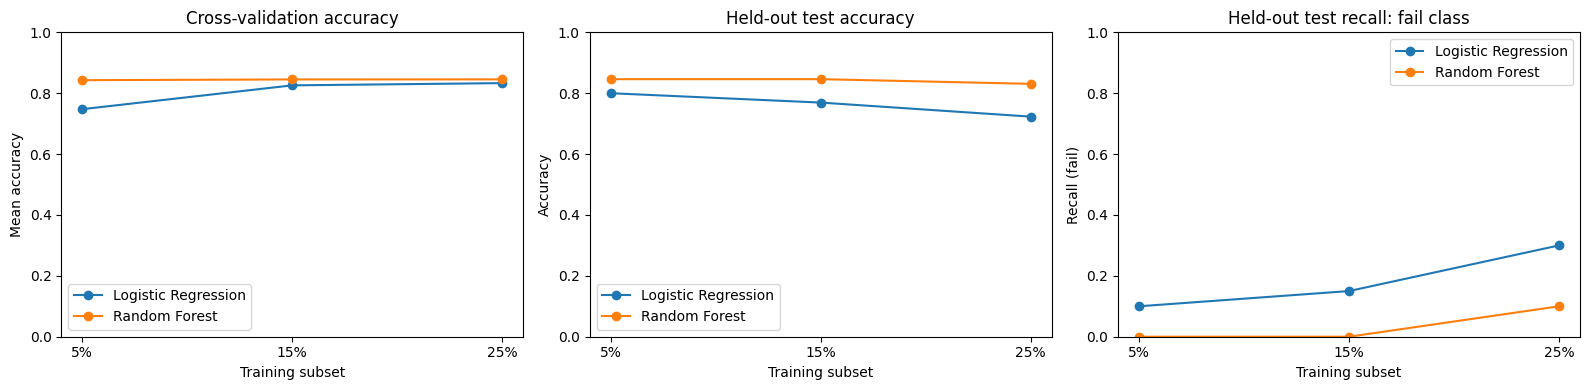

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for model in ['Logistic Regression', 'Random Forest']:
    sub = results_df[results_df['Model'] == model]
    axes[0].plot(sub['Training subset'], sub['CV accuracy mean'], marker='o', label=model)
    axes[1].plot(sub['Training subset'], sub['Test accuracy'], marker='o', label=model)
    axes[2].plot(sub['Training subset'], sub['Test recall (fail)'], marker='o', label=model)

axes[0].set_title('Cross-validation accuracy')
axes[0].set_ylabel('Mean accuracy')
axes[1].set_title('Held-out test accuracy')
axes[1].set_ylabel('Accuracy')
axes[2].set_title('Held-out test recall: fail class')
axes[2].set_ylabel('Recall (fail)')
for ax in axes:
    ax.set_xlabel('Training subset')
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()

## 12. Key observations and limitations

1. **Class imbalance:** The pass class is the majority class. Accuracy alone can therefore conceal weak identification of students who fail.
2. **Overfitting:** Random Forest can achieve very high training accuracy while cross-validation and held-out test scores are lower. This is a warning sign of overfitting, not proof that every prediction is unreliable.
3. **Fail-class detection:** Fail-class recall is reported separately because missing students who may need support is an important practical risk.
4. **Training-size effect:** Each 5%, 15% and 25% training subset is drawn only from the development partition; all are assessed against the same untouched test set. Small subsets have higher sampling uncertainty.
5. **Feature importance:** Random Forest importance indicates predictive contribution within this fitted model. It does not show that a feature causes a student to pass or fail.
6. **Generalisation and fairness:** The dataset represents Portuguese secondary-school students and may not generalise to other populations. Demographic and family variables require careful, non-discriminatory use.
7. **Scope:** The models are exploratory decision-support tools, not a basis for automated high-stakes decisions.

---

**End of notebook.**  
All results were generated from the authentic `student-por.csv` dataset. The final test partition was not used when selecting the three training subsets.